# Full pipeline: features, time-order reconstruction, models, validation, submission

**Question.** Top scores in the Optiver Realized Volatility competition (RMSPE ~0.19) relied on two things a
trading desk would not have: the chronological order of `time_id`s (shuffled by Optiver, recovered by competitors)
and features built from *neighbouring* windows, some of which lie in the future. How much of the edge survives
without them?

Logic lives in `src/rv/`; this notebook calls it in order and plots each step.
`scripts/run_cv.py` runs the same experiment end to end.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rv.baselines import BOOK_TRADE_FEATURES, lightgbm
from rv.cv import orient, reconstruct_time_order
from rv.data import load_features
from rv.experiment import MODELS, add_market_rv, predictions, summarise
from rv.stats import block_bootstrap_diff, fold_table
from rv.features import neighbour_features

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, REPORTS = ROOT / "data", ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

## 1. Features

One row per `(stock_id, time_id)`, built from the 10-minute window of book and trade updates (`rv.features`):

- **Book**: realized volatility of the WAP over the full window and the last 5 min / 2.5 min / 1 min (`rv`, `rv_300`,
  `rv_450`, `rv_540`), RV of the level-2 WAP, mean relative spread, mean depth, mean depth imbalance, number of updates.
- **Trade**: RV of trade prices, volume, number of trades, number of orders.
- **`tick_price`**: the real price level. Prices are normalised to ~1 in each window, but the tick size is $0.01,
  so the smallest gap between distinct normalised prices is `0.01 / real_price`. Not a model feature: it is only
  used to recover time order.

First run reads ~2.5 GB of parquet (about 30 s on 12 cores), then it is cached in `data/features_train.parquet`.

In [2]:
features = add_market_rv(load_features(DATA))
print(features.shape)
features.head()

(428932, 18)


,stock_id,time_id,target,rv,rv_300,rv_450,rv_540,rv_level2,spread,depth,imbalance,n_updates,tick_price,trade_rv,volume,n_trades,n_orders,market_rv
0,0,5,0.004136,0.004499,0.002953,0.001721,0.001246,0.006999,0.000852,323.496689,0.490986,302,193.732285,0.002006,3179.0,40.0,110.0,0.004583
1,0,11,0.001445,0.001204,0.000981,0.000918,0.000779,0.002476,0.000394,411.450000,0.400080,200,199.254349,0.000901,1289.0,30.0,57.0,0.002206
2,0,16,0.002168,0.002369,0.001295,0.001158,0.000323,0.004801,0.000725,416.351064,0.355897,188,209.192215,0.001961,2161.0,25.0,68.0,0.002289
3,0,31,0.002195,0.002574,0.001776,0.000993,0.000931,0.003637,0.000861,435.266667,0.349593,120,216.201233,0.001561,1962.0,15.0,59.0,0.002598
4,0,62,0.001747,0.001894,0.001520,0.001378,0.001035,0.003257,0.000397,343.221591,0.423002,176,214.542404,0.000871,1791.0,22.0,89.0,0.002041


## 2. Recovering the chronological order of `time_id`s

Optiver shuffled the windows, but prices move continuously: two windows close in time have similar price levels
across all 112 stocks. A 1-D t-SNE embedding of the standardised log price cross-section lays the windows out along
the time axis (`cv.reconstruct_time_order`). Prices alone cannot tell forwards from backwards, so `cv.orient` picks the
direction in which each window's target (RV of the *next* 10 minutes) is closer to the following window's RV.
Each candidate direction is scored on its own first sixth of the timeline, which walk-forward only uses for
training: the choice reads no test targets. The t-SNE itself reads prices of all windows (never targets).

In [3]:
pivot = lambda col: features.pivot(index="time_id", columns="stock_id", values=col)
prices, rv, target = pivot("tick_price"), pivot("rv"), pivot("target")

unoriented = reconstruct_time_order(prices)
order = orient(unoriented, rv, target)
print("flipped" if order[0] != unoriented[0] else "kept t-SNE direction")

kept t-SNE direction


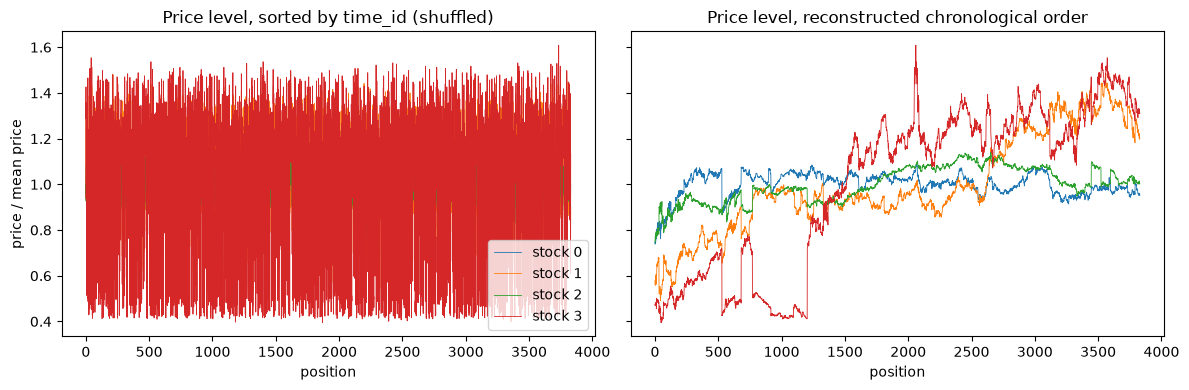

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for stock in [0, 1, 2, 3]:
    axes[0].plot(prices[stock].to_numpy() / prices[stock].mean(), lw=0.6, label=f"stock {stock}")
    axes[1].plot(prices.loc[order, stock].to_numpy() / prices[stock].mean(), lw=0.6)
axes[0].set_title("Price level, sorted by time_id (shuffled)")
axes[1].set_title("Price level, reconstructed chronological order")
axes[0].set_ylabel("price / mean price")
for ax in axes:
    ax.set_xlabel("position")
axes[0].legend()
fig.tight_layout()
fig.savefig(REPORTS / "time_order.png", dpi=120)

Check: if the order is right, a window's target should look like the RV of the window right after it.
Mean absolute log ratio, lower is closer.

In [5]:
r, t = rv.loc[order].to_numpy(), target.loc[order].to_numpy()
gap = lambda a, b: np.nanmean(np.abs(np.log(a / b)))
pd.Series({
    "target_t vs rv_t (same window)": gap(t, r),
    "target_t vs rv_t+1 (next window)": gap(t[:-1], r[1:]),
    "target_t vs rv_t-1 (previous window)": gap(t[1:], r[:-1]),
    "target_t vs rv of a random window": gap(t, r[np.random.default_rng(0).permutation(len(r))]),
}).round(3)

target_t vs rv_t (same window)          0.214
target_t vs rv_t+1 (next window)        0.323
target_t vs rv_t-1 (previous window)    0.345
target_t vs rv of a random window       0.618
dtype: float64

## 3. Neighbour features: where the look-ahead comes from

`features.neighbour_features` averages each stock's RV over the 10 windows whose price cross-section is closest.
Those are the windows nearest in time, **including the ones right after the current window**, whose RV is
almost the target. The production-legal version only looks at earlier windows in the reconstructed order.

In [6]:
nn_all = neighbour_features(features)
nn_legal = neighbour_features(features, order)
cmp = features[["stock_id", "time_id", "target", "rv"]].merge(nn_all, on=["stock_id", "time_id"]).merge(
    nn_legal, on=["stock_id", "time_id"], suffixes=("_all", "_legal"))
log_corr = lambda col: np.log(cmp[[col, "target"]]).corr().iloc[0, 1]
pd.Series({c: log_corr(c) for c in ["rv", "nn_rv_all", "nn_rv_legal"]}, name="corr(log x, log target)").round(3)

rv             0.911
nn_rv_all      0.839
nn_rv_legal    0.765
Name: corr(log x, log target), dtype: float64

## 4. Models under three validation schemes

| Scheme | Folds | Neighbour features |
|---|---|---|
| `random` | 5-fold over shuffled `time_id`s (what most public notebooks report) | from all windows |
| `walk_forward` | train on the past, test on the next block (reconstructed order) | from all windows |
| `walk_forward_legal` | same | from earlier windows only |

Models (`rv.baselines`): naive (current RV), HAR-RV (weighted regression on RV over the last 10/5/1 min),
Kalman local-level filter on log RV per stock, LightGBM on book + trade features with and without neighbour
features. Regression models use sample weight 1/yÃƒâ€šÃ‚Â², which makes squared error equal to squared percentage error.

Gap `random ÃƒÂ¢Ã¢â‚¬Â Ã¢â‚¬â„¢ walk_forward` = optimism from random CV. Gap `walk_forward ÃƒÂ¢Ã¢â‚¬Â Ã¢â‚¬â„¢ walk_forward_legal` = edge that is not
tradeable. Takes ~10 minutes.

In [7]:
preds = predictions(features, order, log=lambda msg: None)
results = summarise(preds)
results.round(4).to_csv(REPORTS / "results.csv")
results.round(4)

,random,walk_forward,walk_forward_legal
naive,0.3414,0.3450,0.3450
har_rv,0.2641,0.2839,0.2839
kalman,0.3100,0.3013,0.3013
lightgbm_no_neighbours,0.2279,0.2760,0.2760
lightgbm,0.2143,0.2441,0.2794


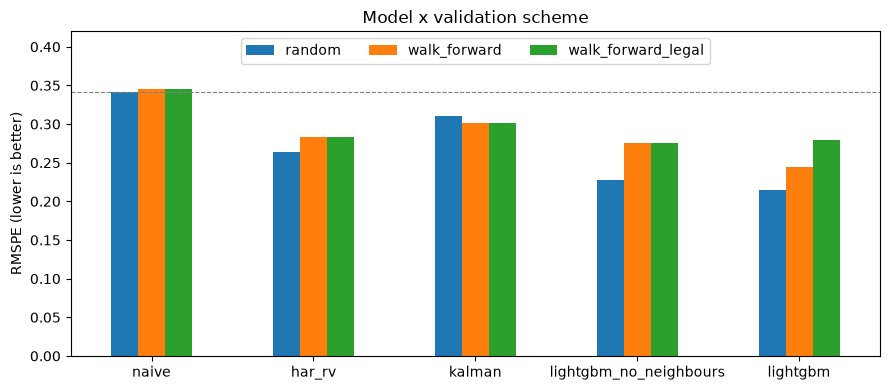

In [8]:
ax = results.plot.bar(figsize=(9, 4), rot=0)
ax.set_ylabel("RMSPE (lower is better)")
ax.set_title("Model x validation scheme")
ax.axhline(results.loc["naive", "random"], color="grey", lw=0.8, ls="--")
ax.set_ylim(0, 0.42)
ax.legend(loc="upper center", ncol=3)
plt.tight_layout()
plt.savefig(REPORTS / "results.png", dpi=120)

### Is the gap real?

Pooled RMSPE hides two things: how results vary across folds, and how noisy a 0.008 difference is.
Fold by fold first (walk-forward, legal features; fold 0 trains on the first sixth of the timeline).

In [9]:
fold_table(preds["walk_forward_legal"], MODELS).round(4)

,naive,har_rv,kalman,lightgbm_no_neighbours,lightgbm
fold,,,,,
0,0.3684,0.3525,0.3069,0.4009,0.4257
1,0.3428,0.2607,0.2983,0.2421,0.2351
2,0.3410,0.2785,0.3001,0.2357,0.2306
3,0.3402,0.2627,0.2907,0.2332,0.2282
4,0.3314,0.2532,0.3102,0.2270,0.2201


Block bootstrap (`rv.stats.block_bootstrap_diff`): errors are correlated across stocks in the same window and
across nearby windows, so resampling rows would overstate certainty. Tested windows in reconstructed order are cut
into blocks of consecutive windows and whole blocks are resampled. Positive `diff` = first model better.

In [10]:
comparisons = [
    ("har_rv", "naive", "walk_forward_legal"),
    ("lightgbm_no_neighbours", "har_rv", "walk_forward_legal"),
    ("lightgbm", "lightgbm_no_neighbours", "walk_forward"),
    ("lightgbm", "lightgbm_no_neighbours", "walk_forward_legal"),
]
pd.DataFrame([
    {"model": a, "vs": b, "scheme": s, "block_size": bs, **block_bootstrap_diff(preds[s], order, a, b, block_size=bs)}
    for a, b, s in comparisons for bs in (20, 100)
]).round(4)

,model,vs,scheme,block_size,diff,ci_low,ci_high,p_a_not_better,n_blocks
0,har_rv,naive,walk_forward_legal,20,0.0611,0.0523,0.0694,0.0000,160
1,har_rv,naive,walk_forward_legal,100,0.0611,0.0469,0.0737,0.0000,32
2,lightgbm_no_neighbours,har_rv,walk_forward_legal,20,0.0079,0.0002,0.0166,0.0240,160
3,lightgbm_no_neighbours,har_rv,walk_forward_legal,100,0.0079,-0.0063,0.0230,0.1395,32
4,lightgbm,lightgbm_no_neighbours,walk_forward,20,0.0319,0.0261,0.0383,0.0000,160
5,lightgbm,lightgbm_no_neighbours,walk_forward,100,0.0319,0.0199,0.0441,0.0000,32
6,lightgbm,lightgbm_no_neighbours,walk_forward_legal,20,-0.0033,-0.0072,0.0004,0.9595,160
7,lightgbm,lightgbm_no_neighbours,walk_forward_legal,100,-0.0033,-0.0093,0.0032,0.8240,32


## 5. Submission file

The competition is a code competition (closed): Kaggle scores it by re-running a notebook on its hidden test set,
so a local CSV cannot be uploaded directly. This builds `submission.csv` in the required format from the
production-legal LightGBM (no neighbour features), trained on all training rows. The local `test.csv` only has
3 rows of stock 0 (two with no book data, filled with the median target); the hidden test set covers every stock.

In [11]:
test = add_market_rv(load_features(DATA, split="test"))
test["target"] = lightgbm(features, test, BOOK_TRADE_FEATURES)
test["target"] = test["target"].fillna(features["target"].median())   # windows with no book data
submission = test.assign(row_id=test["stock_id"].astype(str) + "-" + test["time_id"].astype(str))[["row_id", "target"]]
submission.to_csv(REPORTS / "submission.csv", index=False)
submission

,row_id,target
0,0-4,0.000497
1,0-32,0.003048
2,0-34,0.003048
